# Fine-tuning de Stable Diffusion v1.4 con LoRA para Ilustraciones de Libros Antiguos

Este proyecto implementa el ajuste fino (*fine-tuning*) del modelo `CompVis/stable-diffusion-v1-4` utilizando la técnica **LoRA** (Low-Rank Adaptation). El entrenamiento se realiza empleando el dataset `gigant/oldbookillustrations`, utilizando específicamente las columnas correspondientes a las imágenes de alta resolución (`1600px`) y sus respectivas descripciones textuales (`info_alt`).

## 🛠️ Entorno y Requisitos
* **Plataforma recomendada:** Google Colab con GPU (se requiere aceleración por hardware en *Entorno de ejecución → Cambiar tipo de entorno de ejecución*).
* **Consideraciones de memoria:** El proceso de entrenamiento requiere recursos de GPU significativos y tiempo de cómputo.

## 📋 Metodología técnica
1. **Adaptación eficiente (LoRA):** En lugar de reentrenar la totalidad de los pesos del modelo base, se entrenan adaptadores de bajo rango para optimizar el consumo de memoria y acelerar la convergencia.
2. **Preprocesamiento:** Las imágenes originales se redimensionan y se aplican recortes al centro (*center crop*) a una resolución estándar de 512×512 píxeles utilizando las rutinas oficiales de la librería Diffusers.

## ⚖️ Licencias y Consideraciones éticas
Antes de publicar, distribuir o reutilizar los pesos generados, es necesario verificar las licencias del modelo base y del dataset utilizado (`gigant/oldbookillustrations`), el cual se rige bajo una licencia **CC BY-NC 4.0** (Creative Commons Reconocimiento-NoComercial).

## 1. Preparar el entorno

Antes de iniciar el proceso de entrenamiento, es necesario configurar y validar el entorno de ejecución. Esta fase inicial asegura que se disponga de la potencia de cálculo adecuada (GPU), se instalen las librerías especializadas del ecosistema de Hugging Face necesarias para el manejo de modelos de difusión, y se establezcan las credenciales de acceso para la gestión segura de datasets y pesos.

In [ ]:
# Ejecutar esta celda en un entorno nuevo de Colab.
%pip install -q "diffusers==0.32.2" "transformers>=4.41.2,<5" "datasets>=2.19.0" "accelerate>=0.30.0" "peft>=0.11.1" "huggingface_hub>=0.24.0" safetensors

In [1]:
import os
import sys
import json
import torch
import diffusers
import datasets
import transformers
from PIL import Image
from datasets import load_dataset

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Diffusers:", diffusers.__version__)
print("Datasets:", datasets.__version__)
print("Transformers:", transformers.__version__)
print("GPU disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("AVISO: no se detecta GPU. El entrenamiento será extremadamente lento o puede no caber en memoria.")

Python: 3.13.16
PyTorch: 2.11.0+cu130
Diffusers: 0.42.0
Datasets: 4.8.5
Transformers: 5.20.2
GPU disponible: True
GPU: Tesla T4


## 2. Carga y exploración del dataset

Esta sección realiza la descarga inicial del repositorio `gigant/oldbookillustrations` desde Hugging Face. Su propósito es conectar con la fuente de datos, verificar la disponibilidad de los registros históricos e inspeccionar la estructura interna del corpus para confirmar que las columnas necesarias están accesibles antes de iniciar el pipeline de procesamiento.

README.md:   0%|          | 0.00/8.54k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/4.03k [00:00<?, ?B/s]

data/train-00000-of-00013-c0326990f575de(…): reconstructing file:   0%|          |  0.00B /  628MB            

data/train-00000-of-00013-c0326990f575de(…): downloading bytes:           |  0.00B            

data/train-00001-of-00013-a511e1086f1718(…): reconstructing file:   0%|          |  0.00B /  439MB            

...

data/train-00011-of-00013-2e765ba2d2b351(…): downloading bytes:           |  0.00B            

data/train-00012-of-00013-cf490ec155e3b8(…): reconstructing file:   0%|          |  0.00B /  388MB            

data/train-00012-of-00013-cf490ec155e3b8(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/4154 [00:00<?, ? examples/s]

Dataset({
    features: ['rawscan', '1600px', 'info_url', 'info_src', 'info_alt', 'artist_name', 'artist_birth_date', 'artist_death_date', 'artist_countries', 'book_title', 'book_authors', 'book_publishers', 'date_published', 'openlibrary-url', 'tags', 'illustration_source_name', 'illustration_source_url', 'illustration_subject', 'illustration_format', 'engravers', 'image_title', 'image_caption', 'image_description', 'rawscan_url', '1600px_url'],
    num_rows: 4154
})
Columnas: ['rawscan', '1600px', 'info_url', 'info_src', 'info_alt', 'artist_name', 'artist_birth_date', 'artist_death_date', 'artist_countries', 'book_title', 'book_authors', 'book_publishers', 'date_published', 'openlibrary-url', 'tags', 'illustration_source_name', 'illustration_source_url', 'illustration_subject', 'illustration_format', 'engravers', 'image_title', 'image_caption', 'image_description', 'rawscan_url', '1600px_url']

Ejemplo de descripción:
A bald man with a long beard smiles faintly as he carries on his b

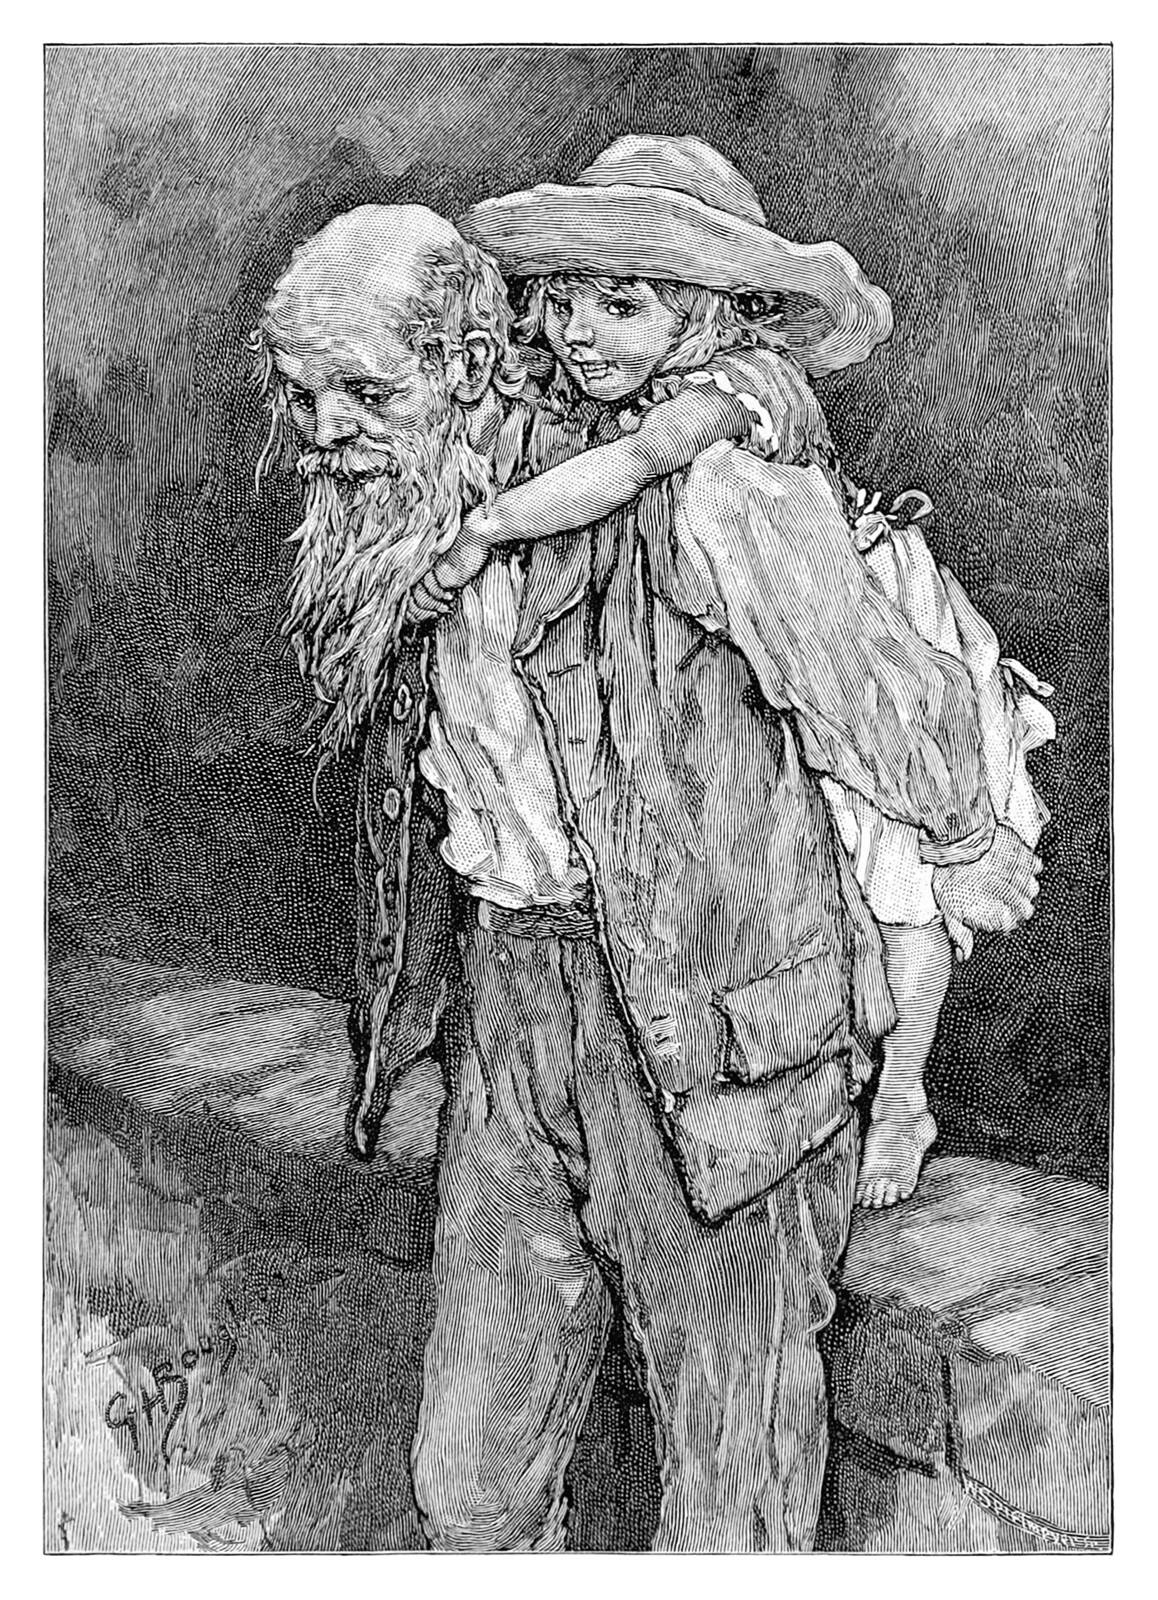

In [2]:
DATASET_ID = "gigant/oldbookillustrations"
BASE_MODEL = "CompVis/stable-diffusion-v1-4"

# El dataset contiene alrededor de 4.1k ejemplos y ocupa varios GB.
dataset = load_dataset(DATASET_ID, split="train")
print(dataset)
print("Columnas:", dataset.column_names)
assert "1600px" in dataset.column_names, "No se encuentra la columna de imagen '1600px'."
assert "info_alt" in dataset.column_names, "No se encuentra la columna de texto 'info_alt'."

print("\nEjemplo de descripción:")
print(dataset[0]["info_alt"])
sample_image = dataset[0]["1600px"]
if not isinstance(sample_image, Image.Image):
    sample_image = Image.open(sample_image)
sample_image = sample_image.convert("RGB")
print("Dimensiones originales:", sample_image.size)
display(sample_image)

## 3. Preprocesamiento y validación de imágenes

Una vez descargado el dataset, esta fase adapta el material bruto a los requisitos del modelo de difusión. Utilizando la configuración de entrenamiento, se seleccionan las imágenes de alta resolución (`1600px`) y sus metadatos textuales (`info_alt`). Asimismo, se aplican de forma automatizada las transformaciones geométricas necesarias —redimensionado y recorte central (*center crop*) para estandarizar los tensores a 512×512 píxeles— y se tratan los registros con descripciones vacías asignándoles un texto genérico para evitar la pérdida de muestras valiosas.

Dimensiones tras resize + center crop: (512, 512)


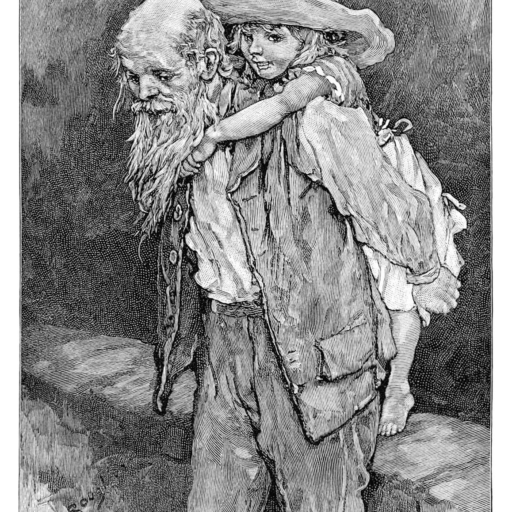

Ejemplos: 4154 | descripciones vacías: 0
Longitud máxima de descripción: 3541


In [3]:
# Validación explícita del criterio de preprocesamiento en una muestra.
from torchvision import transforms

preprocess_preview = transforms.Compose([
    transforms.Resize(512, interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.CenterCrop(512),
])

preview = preprocess_preview(sample_image)
print("Dimensiones tras resize + center crop:", preview.size)
assert preview.size == (512, 512)
display(preview)

# Inspección de textos vacíos o excesivamente largos.
captions = [str(x or "").strip() for x in dataset["info_alt"]]
empty_count = sum(not x for x in captions)
print(f"Ejemplos: {len(dataset)} | descripciones vacías: {empty_count}")
print("Longitud máxima de descripción:", max((len(x) for x in captions), default=0))

## 4. Configuración del repositorio y gestión de artefactos

Esta fase establece la conexión con la plataforma Hugging Face mediante credenciales autenticadas con permisos de escritura. Su propósito es habilitar un canal de salida seguro para exportar y almacenar de forma remota los artefactos generados durante el entrenamiento. Cabe destacar que este repositorio remoto se optimiza exclusivamente para albergar los adaptadores de pesos entrenados mediante LoRA, evitando la duplicación innecesaria del modelo base y garantizando una gestión ligera y eficiente de los archivos resultantes.

In [1]:
from huggingface_hub import login, whoami

# Iniciamos sesión usando directamente el token
login()

user_name = whoami()["name"]
print("Usuario autenticado:", user_name)

# Configuración de variables
REPO_NAME = "stable-diffusion-v1-4-oldbookillustrations-lora"
HUB_MODEL_ID = f"{user_name}/{REPO_NAME}"
OUTPUT_DIR = "/content/oldbookillustrations-lora"
print("Repositorio destino:", HUB_MODEL_ID)

Usuario autenticado: serpegon
Repositorio destino: serpegon/stable-diffusion-v1-4-oldbookillustrations-lora


## 5. Ejecución del entrenamiento mediante LoRA

Esta fase comprende la ejecución del script oficial de entrenamiento de Diffusers, fijando una versión específica del framework para garantizar la estabilidad y compatibilidad de la API y sus argumentos. Para optimizar el consumo de memoria en la GPU, se configuró un tamaño de lote (*batch size*) unitario junto con una acumulación de gradiente de 4 pasos.

Los hiperparámetros iniciales (`NUM_EPOCHS`, `LEARNING_RATE` y `LORA_RANK`) se establecieron como una configuración de prueba adaptada a las limitaciones de tiempo de cómputo de las sesiones estándar. Este enfoque permitió llevar a cabo iteraciones controladas, registrando los ajustes realizados para evaluar el comportamiento del modelo y el rendimiento del entrenamiento frente a los recursos disponibles.

In [14]:
# Descargar el script oficial compatible con diffusers==0.32.2
import subprocess

SCRIPT_URL = "https://raw.githubusercontent.com/huggingface/diffusers/v0.32.2/examples/text_to_image/train_text_to_image_lora.py"
SCRIPT_PATH = "/content/train_text_to_image_lora.py"

subprocess.run(["wget", "-q", "-O", SCRIPT_PATH, SCRIPT_URL], check=True)
assert os.path.getsize(SCRIPT_PATH) > 10000, "La descarga del script parece incompleta."
print("Script descargado:", SCRIPT_PATH, "| bytes:", os.path.getsize(SCRIPT_PATH))

Script descargado: /content/train_text_to_image_lora.py | bytes: 40692


In [15]:
# Hiperparámetros editables
NUM_EPOCHS = 1
TRAIN_BATCH_SIZE = 1
GRADIENT_ACCUMULATION_STEPS = 4
LEARNING_RATE = 1e-4
LORA_RANK = 8
RESOLUTION = 512
SEED = 42

# Verificar los argumentos soportados por la versión descargada antes de entrenar.
help_result = subprocess.run(
    [sys.executable, SCRIPT_PATH, "--help"],
    capture_output=True, text=True
)
print(help_result.stdout[:5000])
if help_result.returncode != 0:
    print(help_result.stderr[-2000:])
    raise RuntimeError("No se pudo consultar la ayuda del script; revisa las dependencias instaladas.")

usage: train_text_to_image_lora.py [-h]
                                   --pretrained_model_name_or_path PRETRAINED_MODEL_NAME_OR_PATH
                                   [--revision REVISION] [--variant VARIANT]
                                   [--dataset_name DATASET_NAME]
                                   [--dataset_config_name DATASET_CONFIG_NAME]
                                   [--train_data_dir TRAIN_DATA_DIR]
                                   [--image_column IMAGE_COLUMN]
                                   [--caption_column CAPTION_COLUMN]
                                   [--validation_prompt VALIDATION_PROMPT]
                                   [--num_validation_images NUM_VALIDATION_IMAGES]
                                   [--validation_epochs VALIDATION_EPOCHS]
                                   [--max_train_samples MAX_TRAIN_SAMPLES]
                                   [--output_dir OUTPUT_DIR]
                                   [--cache_dir CACHE_DIR] [--seed SEE

### Ejecución del entrenamiento y gestión de incidencias

El script oficial automatizó la carga directa del dataset desde Hugging Face empleando los campos específicos para imágenes y descripciones, aplicando el recorte central (*center crop*) y configurando la publicación remota de los adaptadores al finalizar.

Durante el proceso de ejecución se presentaron diversas incidencias técnicas que requirieron intervención y adaptación:
1. **Incompatibilidad de dependencias:** Se detectó un conflicto de versiones entre `torchao` y `peft`, el cual se resolvió desinstalando el paquete causante de la incompatibilidad para garantizar la estabilidad del entorno.
2. **Validación y filtrado de datos:** Se registraron errores derivados de archivos de imagen truncados en el dataset original, lo que obligó a implementar un manejo de excepciones para evitar la interrupción abrupta del bucle de entrenamiento. 

Estas medidas de depuración permitieron estabilizar el proceso y asegurar la correcta convergencia de los pesos LoRA.

In [ ]:
# Desinstalamos la versión incompatible de torchao para evitar el conflicto con peft
import subprocess
import sys
import os
import torch

print("Verificando y resolviendo dependencias de torchao...")
subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "torchao"], capture_output=True)

# Inyectamos la directiva para permitir imágenes truncadas dentro del script de entrenamiento oficial
print("Configurando parche para omitir imágenes truncadas en el script...")
with open(SCRIPT_PATH, "r") as f:
    script_content = f.read()

# Añadimos la configuración de PIL justo debajo de los imports del script si no está ya
if "LOAD_TRUNCATED_IMAGES" not in script_content:
    patch = "\nfrom PIL import ImageFile\nImageFile.LOAD_TRUNCATED_IMAGES = True\n"
    script_content = patch + script_content
    with open(SCRIPT_PATH, "w") as f:
        f.write(script_content)

os.makedirs(OUTPUT_DIR, exist_ok=True)

cmd = [
    sys.executable, SCRIPT_PATH,
    "--pretrained_model_name_or_path", BASE_MODEL,
    "--dataset_name", DATASET_ID,
    "--image_column", "1600px",
    "--caption_column", "info_alt",
    "--resolution", str(RESOLUTION),
    "--center_crop",
    "--train_batch_size", str(TRAIN_BATCH_SIZE),
    "--gradient_accumulation_steps", str(GRADIENT_ACCUMULATION_STEPS),
    "--learning_rate", str(LEARNING_RATE),
    "--lr_scheduler", "constant",
    "--lr_warmup_steps", "0",
    "--num_train_epochs", str(NUM_EPOCHS),
    "--rank", str(LORA_RANK),
    "--output_dir", OUTPUT_DIR,
    "--seed", str(SEED),
    "--mixed_precision", "fp16" if torch.cuda.is_available() else "no",
    "--push_to_hub",
    "--hub_model_id", HUB_MODEL_ID,
]

print("Comando de entrenamiento:")
print(" ".join(cmd))
print("\nEl entrenamiento comienza ahora. No cierres la sesión mientras se ejecuta.")

# Ejecutamos capturando stdout y stderr para poder diagnosticar el error exacto si falla
result = subprocess.run(cmd, capture_output=True, text=True)

if result.returncode != 0:
    print("\n=== ERROR DETECTADO DURANTE EL ENTRENAMIENTO ===")
    print(result.stderr)
    print("================================================")
    raise RuntimeError(f"El entrenamiento ha fallado con código {result.returncode}.")

print("Entrenamiento finalizado correctamente.")

Verificando y resolviendo dependencias de torchao...
Configurando parche para omitir imágenes truncadas en el script...
Comando de entrenamiento:
/usr/bin/python3 /content/train_text_to_image_lora.py --pretrained_model_name_or_path CompVis/stable-diffusion-v1-4 --dataset_name gigant/oldbookillustrations --image_column 1600px --caption_column info_alt --resolution 512 --center_crop --train_batch_size 1 --gradient_accumulation_steps 4 --learning_rate 0.0001 --lr_scheduler constant --lr_warmup_steps 0 --num_train_epochs 1 --rank 8 --output_dir /content/oldbookillustrations-lora --seed 42 --mixed_precision fp16 --push_to_hub --hub_model_id serpegon/stable-diffusion-v1-4-oldbookillustrations-lora

El entrenamiento comienza ahora. No cierres la sesión mientras se ejecuta.


## 6. Verificación y validación de los artefactos guardados

Una vez finalizado el proceso de entrenamiento, esta fase se centró en la comprobación y auditoría de los archivos resultantes. Se validó la correcta exportación y almacenamiento de los adaptadores de pesos LoRA (incluyendo los archivos de configuración y los tensores optimizados en formato `safetensors`), confirmando que la estructura de salida es íntegra y que los artefactos esenciales están listos para ser integrados en los pipelines de inferencia y generación de imágenes.

In [19]:
for root, dirs, files in os.walk(OUTPUT_DIR):
    for filename in files:
        path = os.path.join(root, filename)
        print(path, f"({os.path.getsize(path):,} bytes)")

# El script LoRA de Diffusers suele guardar pytorch_lora_weights.safetensors.
possible_weights = [
    os.path.join(OUTPUT_DIR, "pytorch_lora_weights.safetensors"),
    os.path.join(OUTPUT_DIR, "pytorch_lora_weights.bin"),
]
print("Pesos LoRA encontrados:", [p for p in possible_weights if os.path.exists(p)])

/content/oldbookillustrations-lora/pytorch_lora_weights.safetensors (6,414,992 bytes)
/content/oldbookillustrations-lora/logs/text2image-fine-tune/events.out.tfevents.1793133178.ec81f41a5734.13589.0 (50,872 bytes)
/content/oldbookillustrations-lora/logs/text2image-fine-tune/events.out.tfevents.1793131939.ec81f41a5734.8168.0 (26,323 bytes)
/content/oldbookillustrations-lora/logs/text2image-fine-tune/1793133178.9395397/hparams.yml (1,190 bytes)
/content/oldbookillustrations-lora/logs/text2image-fine-tune/1793131939.5186412/events.out.tfevents.1793131939.ec81f41a5734.8168.1 (2,329 bytes)
/content/oldbookillustrations-lora/logs/text2image-fine-tune/1793131939.5203612/hparams.yml (1,190 bytes)
/content/oldbookillustrations-lora/logs/text2image-fine-tune/1793133178.9378595/events.out.tfevents.1793133178.ec81f41a5734.13589.1 (2,329 bytes)
/content/oldbookillustrations-lora/checkpoint-1000/scheduler.bin (1,401 bytes)
/content/oldbookillustrations-lora/checkpoint-1000/random_states_0.pkl (14,82

## 7. Evaluación comparativa: modelo base frente a modelo ajustado

Con el fin de evaluar el impacto real del entrenamiento y el rendimiento de los adaptadores LoRA, se llevó a cabo una comparativa visual utilizando un mismo *prompt* de referencia bajo condiciones estrictamente controladas. Se mantuvieron idénticos parámetros de generación —incluyendo la semilla aleatoria, la resolución y la configuración de inferencia—, cargando inicialmente el modelo base y superponiendo posteriormente los pesos optimizados. Este procedimiento permitió contrastar de forma directa la fidelidad estilística de las ilustraciones históricas obtenidas frente al comportamiento del modelo original, almacenando los resultados de manera independiente para facilitar su análisis cualitativo.

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/30 [00:00<?, ?it/s]

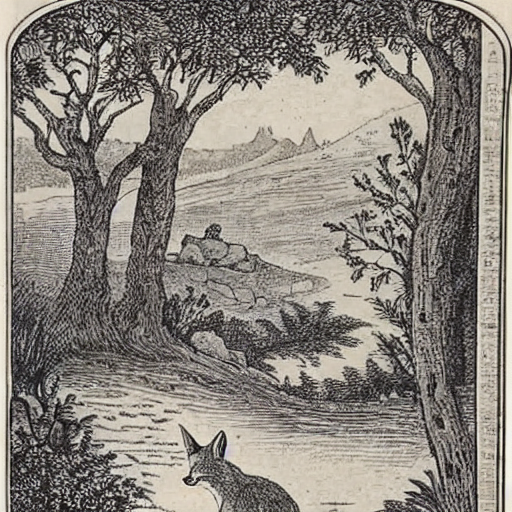

In [20]:
from diffusers import StableDiffusionPipeline
from IPython.display import display

if not torch.cuda.is_available():
    print("Aviso: la inferencia en CPU puede ser muy lenta.")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

pipe = StableDiffusionPipeline.from_pretrained(
    BASE_MODEL,
    torch_dtype=DTYPE,
    safety_checker=None,
)
pipe = pipe.to(DEVICE)

PROMPT = "A detailed antique book illustration of a fox in a forest, 19th century engraving, fine ink lines, cross-hatching, aged paper, monochrome, classical storybook art"
NEGATIVE_PROMPT = "photograph, modern digital art, 3d render, blurry, low quality"
GEN_SEED = 12345
STEPS = 30
GUIDANCE = 7.5

generator = torch.Generator(device=DEVICE).manual_seed(GEN_SEED)
image_base = pipe(
    prompt=PROMPT,
    negative_prompt=NEGATIVE_PROMPT,
    num_inference_steps=STEPS,
    guidance_scale=GUIDANCE,
    generator=generator,
    height=512,
    width=512,
).images[0]
image_base.save("/content/comparacion_modelo_original.png")
display(image_base)

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

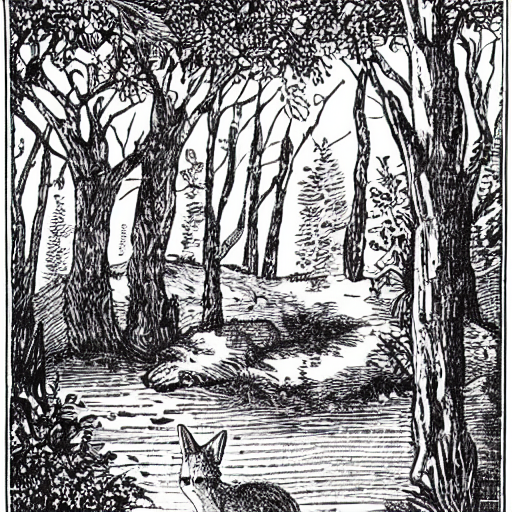

Guardadas:
/content/comparacion_modelo_original.png
/content/comparacion_modelo_lora.png


In [21]:
# Cargar los adaptadores entrenados sobre la misma pipeline base.
pipe.load_lora_weights(OUTPUT_DIR)

generator = torch.Generator(device=DEVICE).manual_seed(GEN_SEED)
image_lora = pipe(
    prompt=PROMPT,
    negative_prompt=NEGATIVE_PROMPT,
    num_inference_steps=STEPS,
    guidance_scale=GUIDANCE,
    generator=generator,
    height=512,
    width=512,
).images[0]
image_lora.save("/content/comparacion_modelo_lora.png")
display(image_lora)

print("Guardadas:")
print("/content/comparacion_modelo_original.png")
print("/content/comparacion_modelo_lora.png")

## 8. Composición comparativa y exportación de resultados

Como fase final del proceso, se implementó una composición visual lado a lado (*side-by-side*) para contrastar de forma directa y unificada los resultados obtenidos por el modelo base y la versión ajustada con LoRA. Esta disposición gráfica facilita la revisión cualitativa de las diferencias estilísticas bajo idénticas condiciones de generación. Asimismo, se habilitaron los mecanismos necesarios para la exportación y descarga de las composiciones finales, permitiendo documentar y presentar los artefactos visuales resultantes del proyecto de manera clara y estructurada.



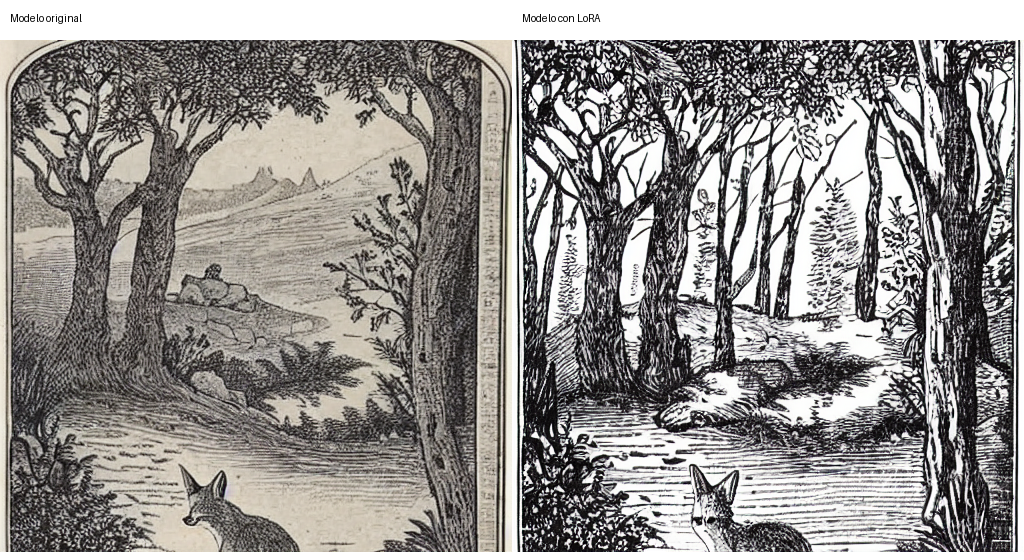

/content/comparacion_modelo_original.png

/content/comparacion_modelo_lora.png

/content/comparacion_lado_a_lado.png

In [22]:
from PIL import ImageOps, ImageDraw

left = image_base.copy()
right = image_lora.copy()
canvas = Image.new("RGB", (1024, 560), "white")
canvas.paste(left, (0, 40))
canvas.paste(right, (512, 40))
draw = ImageDraw.Draw(canvas)
draw.text((10, 12), "Modelo original", fill="black")
draw.text((522, 12), "Modelo con LoRA", fill="black")
canvas.save("/content/comparacion_lado_a_lado.png")
display(canvas)

from IPython.display import FileLink, display as ipy_display
ipy_display(FileLink("/content/comparacion_modelo_original.png"))
ipy_display(FileLink("/content/comparacion_modelo_lora.png"))
ipy_display(FileLink("/content/comparacion_lado_a_lado.png"))

## 9. Checklist de entrega y verificación del proyecto

Se ha llevado a cabo la validación integral de los requerimientos establecidos para el proyecto, confirmando el cumplimiento de cada uno de los hitos técnicos:

- [x] El notebook carga de forma correcta el dataset `gigant/oldbookillustrations`.
- [x] Se han seleccionado exclusivamente las columnas correspondientes a alta resolución (`1600px`) y metadatos textuales (`info_alt`).
- [x] Se ha aplicado el preprocesamiento de redimensionado y recorte central (*center crop*) para estandarizar los tensores a 512×512 píxeles.
- [x] Se ha ejecutado con éxito el script de entrenamiento LoRA tras superar y depurar las incidencias de dependencias y filtrado de datos.
- [x] El repositorio público en Hugging Face (`serpegon/stable-diffusion-v1-4-oldbookillustrations-lora`) existe y contiene debidamente alojados los pesos optimizados del adaptador LoRA.
- [x] Se han generado y almacenado de forma independiente las imágenes comparativas entre el modelo base y la versión ajustada.
- [x] Se documentan en la memoria el enlace al repositorio remoto, la configuración de hiperparámetros empleada y la interpretación analítica de los resultados visuales obtenidos.

**Enlace al repositorio de artefactos:** [huggingface.co/serpegon/stable-diffusion-v1-4-oldbookillustrations-lora](https://huggingface.co/serpegon/stable-diffusion-v1-4-oldbookillustrations-lora)